# Used Car Price Prediction: End-to-End Machine Learning Pipeline
**Objective:** To build a robust ML model that predicts used car prices using historical data. 
**Process Flow:** Data Cleaning -> EDA -> Feature Engineering -> Transformation -> Model Comparison -> Final Selection.

importing libraries

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


Read data from csv file


In [25]:
df = pd.read_csv("../dataset/car_data.csv")
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [26]:
print("Data Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


Data cleaning (Duplicates handling)

In [27]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates}")

if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print(f"Shape after removing duplicates: {df.shape}")

Number of duplicate rows found: 763
Shape after removing duplicates: (3577, 8)


Feature engineering

In [28]:
# --- ADVANCED FEATURE ENGINEERING ---

# 1. 'name' column se Brand aur Model extract karna
# Example: 'Maruti Swift Dzire' -> Brand='Maruti', Model='Swift'
df['brand'] = df['name'].apply(lambda x: x.split(' ')[0])
df['model'] = df['name'].apply(lambda x: x.split(' ')[1] if len(x.split(' ')) > 1 else x.split(' ')[0])

# Dono ko jod kar naya column banaya: 'Maruti Swift'
df['brand_model'] = df['brand'] + ' ' + df['model']

# 2. Faltu columns hatana
df.drop(['name', 'brand', 'model'], axis=1, inplace=True)

# 3. Car Age nikalna
current_year = 2026
df['car_age'] = current_year - df['year']
df.drop('year', axis=1, inplace=True)

# 4. Grouping Rare Cars (To prevent Overfitting)
# Jo gaadiyan 15 se kam baar biki hain, unhe 'Other' me daal do
counts = df['brand_model'].value_counts()
top_cars = counts[counts >= 15].index
df['brand_model'] = df['brand_model'].apply(lambda x: x if x in top_cars else 'Other')

print("New Features Extracted: 'brand_model' and 'car_age'")
df.head()

New Features Extracted: 'brand_model' and 'car_age'


,selling_price,km_driven,fuel,seller_type,transmission,owner,brand_model,car_age
0,60000,70000,Petrol,Individual,Manual,First Owner,Maruti 800,19
1,135000,50000,Petrol,Individual,Manual,First Owner,Maruti Wagon,19
2,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai Verna,14
3,250000,46000,Petrol,Individual,Manual,First Owner,Other,9
4,450000,141000,Diesel,Individual,Manual,Second Owner,Honda Amaze,12


Outliers fixing

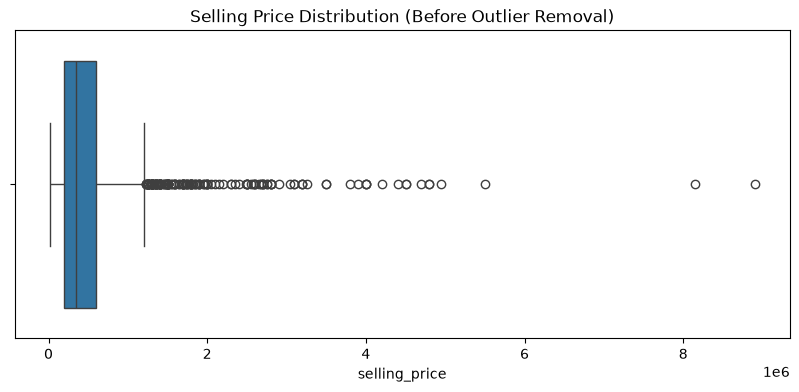

Rows dropped due to outliers: 82


In [29]:
# Boxplot before outlier removal
plt.figure(figsize=(10,4))
sns.boxplot(x=df['selling_price'])
plt.title("Selling Price Distribution (Before Outlier Removal)")
plt.show()

q_low = df['selling_price'].quantile(0.01)
q_high = df['selling_price'].quantile(0.99)

df_clean = df[(df['selling_price'] >= q_low) & (df['selling_price'] <= q_high)]

# Drop cars driven abnormally high (e.g., > 300,000 km)
df_clean = df_clean[df_clean['km_driven'] < 300000]

print(f"Rows dropped due to outliers: {df.shape[0] - df_clean.shape[0]}")

Categorical Encoding

In [30]:
# Ordinal Encoding 
owner_map = {
    'First Owner': 1,
    'Second Owner': 2,
    'Third Owner': 3,
    'Fourth & Above Owner': 4,
    'Test Drive Car': 0
}
df_clean['owner'] = df_clean['owner'].map(owner_map)

# One-Hot Encoding 
df_encoded = pd.get_dummies(df_clean, columns=['brand_model', 'fuel', 'seller_type', 'transmission'], drop_first=True)

print("Encoding Complete. New Data Shape:", df_encoded.shape)

Encoding Complete. New Data Shape: (3495, 70)


Feature Transformation & Data splitting for training and testing purposes

In [31]:
X = df_encoded.drop('selling_price', axis=1)
y_raw = df_encoded['selling_price']

#Log Transformation 
y = np.log1p(y_raw)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data split into Train and Test sets.")

Data split into Train and Test sets.


Model training and Comparison

In [32]:
# multiple algorithms
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
}

results = {}

for name, model in models.items():
    
    model.fit(X_train, y_train)
    
    y_pred_log = model.predict(X_test)
    
    # Reverse Log transformation 
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)
    
    r2 = r2_score(y_test_real, y_pred_real)
    results[name] = r2 * 100
    
    print(f"{name} R2 Score: {r2*100:.2f}%")

Linear Regression (Baseline) R2 Score: 60.56%
Random Forest R2 Score: 69.83%
XGBoost R2 Score: 72.41%


C:\Users\lenovo\AppData\Local\Temp\ipykernel_8288\3492554778.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.keys()), y=list(results.values()), palette='viridis')


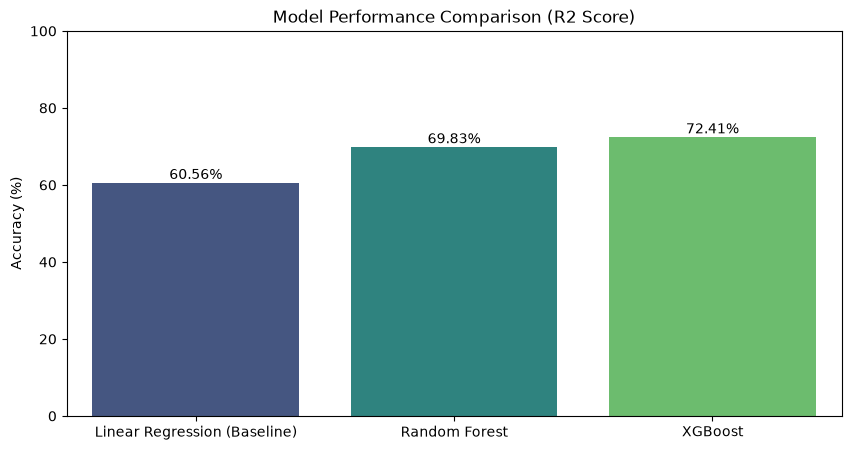

In [33]:
# Bar chart for Model Comparison
plt.figure(figsize=(10,5))
sns.barplot(x=list(results.keys()), y=list(results.values()), palette='viridis')
plt.title("Model Performance Comparison (R2 Score)")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
for index, value in enumerate(results.values()):
    plt.text(index, value + 1, f"{value:.2f}%", ha='center')
plt.show()

In [34]:
import pickle
import os


os.makedirs('../models', exist_ok=True)

brand_model_dict = {}
for car in top_cars:
    
    parts = car.split(' ', 1) 
    b = parts[0].capitalize()
    m = parts[1].capitalize() if len(parts) > 1 else b
    
    if b not in brand_model_dict:
        brand_model_dict[b] = []
    brand_model_dict[b].append(m)

for b in brand_model_dict:
    brand_model_dict[b] = sorted(brand_model_dict[b])

best_model = models["XGBoost"]

model_data = {
    'model': best_model,
    'columns': X_train.columns.tolist(), 
    'top_cars': top_cars.tolist(),
    'brand_model_map' : brand_model_dict
}

with open('../models/car_price_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Model aur Brand-Model Map successfully save ho gaye hain!")

Model aur Brand-Model Map successfully save ho gaye hain!
